<a href="https://colab.research.google.com/github/Andru-1987/data_science_ii_96085/blob/main/14_semana/clase_practica/clasificacion_inactivos_airbnb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de avisos inactivos en Airbnb Buenos Aires

**Validación, selección de modelo y optimización de hiperparámetros con `Pipeline`**

Esta clase lleva a clasificación los conceptos de la clase de regresión (bias-varianza, validación cruzada, tuning controlado y anti-patrones). La pregunta de negocio es:

> Con las características de un aviso (ubicación, precio, tipo, disponibilidad, tamaño del host), ¿podemos detectar cuáles están **inactivos** (0 reviews en los últimos 12 meses) para priorizar una auditoría de oferta?

**Qué se responde en el recorrido:**
1. ¿Qué modelo conviene: uno lineal o uno de árboles? ¿Es un problema lineal?
2. ¿Cuánto mejora el tuning y con cuántas iteraciones?
3. ¿Dónde cortamos la probabilidad para auditar con una precisión aceptable?

**Mapa de la clase:**

| Sección | Eje del README |
|---|---|
| 2 a 4: Target, features sin fuga, split y pipeline | Eje 4 (anti-patrones) |
| 5 a 7: Validación y selección de modelo | Eje 2 |
| 8: Curva de complejidad | Eje 1 |
| 9 a 11: Tuning, umbral y evaluación final | Eje 3 |

## 1. Entorno y configuración

`CV` se define una sola vez y se reutiliza en todo el notebook (DRY). Con una semilla fija, todos los modelos se evalúan sobre exactamente los mismos folds, lo que hace pareadas las comparaciones.

In [ ]:
%pip install -q optuna

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, train_test_split,
                                     validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

SEED = 42
URL = "https://raw.githubusercontent.com/Andru-1987/csv_files_ds/refs/heads/main/buenos_aires.csv"
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORE = "average_precision"          # métrica de tuning (PR-AUC)
N_TRIALS = 10                        # presupuesto por tuner

## 2. Población y target

**Población.** Se descartan los avisos con `minimum_nights >= 30`. Son otro producto (alquiler de estadía larga) en el que pocas reviews turísticas es lo normal, y mezclarlos le quitaría significado a "inactivo". Es la misma regla 1 de la capa de reglas de negocio del clustering.

**Target.** `inactivo = 1` si `number_of_reviews_ltm == 0`.

**Una sola transformación previa.** `log_price` se calcula antes del split porque es una operación fila a fila (no usa estadísticos del conjunto), así que no hay fuga. No se winsoriza ni se calcula `precio_rel`: ambos usan estadísticos de todo el dataset y filtrarían información del test.

In [ ]:
df = pd.read_csv(URL).drop_duplicates()
df = df[df.minimum_nights.notna() & (df.minimum_nights < 30)]
df = df.assign(log_price=np.log1p(df.price))          # price nulo queda nulo: lo imputa el pipeline

y = (df.number_of_reviews_ltm == 0).astype(int)       # 1 = inactivo
print(f"Avisos: {len(df):,} | Prevalencia de inactivos: {y.mean():.1%}")
print("Nulos en number_of_reviews_ltm:", df.number_of_reviews_ltm.isna().sum())

Avisos: 28,956 | Prevalencia de inactivos: 21.4%
Nulos en number_of_reviews_ltm: 0


**Qué mirar:** la prevalencia (alrededor de 20% en el análisis previo) es también el **piso de PR-AUC** de un modelo sin información. Si hubiera nulos en `number_of_reviews_ltm`, la comparación `== 0` los contaría silenciosamente como activos: conviene que sean cero.

## 3. Features sin fuga (el paso más importante)

Las variables que definen o delatan el target **no pueden estar en `X`**:

| Variable | Decisión | Motivo |
|---|---|---|
| `number_of_reviews_ltm` | Fuera | Es el target |
| `number_of_reviews`, `reviews_per_month`, `last_review` | Fuera | Si hubo reviews en el último año, estas son mayores que cero: delatan el target |
| `availability_365` | **Dentro** | No es fuga estricta, pero es en parte consecuencia de estar inactivo (calendario siempre abierto). La sección 6 mide cuánto aporta |

Esta es la versión de clasificación del *data leakage*. Ejercicio sugerido para los alumnos: agregar `number_of_reviews` a `NUM` y ver cómo se dispara el score.

In [ ]:
NUM = ["latitude", "longitude", "log_price", "minimum_nights",
       "calculated_host_listings_count", "availability_365"]
CAT = ["neighbourhood", "room_type"]

X = df[NUM + CAT]

## 4. Split estratificado y pipeline único

`stratify=y` mantiene la proporción de inactivos en train y test. **Desde acá `X_test` no se toca hasta la sección 11.**

`build_pipeline` es la única fuente del preprocesamiento. Imputación y escalado viven dentro del pipeline, de modo que en cada fold se ajustan solo con los datos de entrenamiento (sin fuga por preprocesamiento). Con `bins=True` se reemplaza el escalado por una discretización de las numéricas en tramos: la Logística aprende un peso por tramo y puede capturar relaciones no lineales sin perder interpretabilidad.

**Notas:**
- El paso del modelo se llama siempre `"model"`, por eso todos los hiperparámetros llevan el prefijo `model__`.
- No se usa `class_weight`: la métrica de tuning solo depende del ranking y el umbral se elige más adelante con las curvas out-of-fold, así que los pesos no aportan y distorsionan las probabilidades.
- Es esperable una advertencia de `KBinsDiscretizer` por tramos repetidos en variables como `availability_365` (muchos avisos en 0 o 365).

In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

def build_pipeline(model, num_cols=NUM, bins=False):
    transform = (KBinsDiscretizer(n_bins=8, encode="onehot", strategy="quantile")
                 if bins else StandardScaler())
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("tr", transform)]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ], sparse_threshold=0)

    return Pipeline([("prep", prep), ("model", model)])



## 5. Validación cruzada: ¿Logística, Logística + bins o Random Forest? (Eje 2)

Se comparan cuatro modelos con 5 folds estratificados, reportando **media ± desvío** de tres métricas:

- **ROC-AUC y PR-AUC:** miden qué tan bien ordena el modelo, sin depender de un umbral. La PR-AUC se centra en la clase minoritaria.
- **F1 a umbral 0,5:** referencia. Depende del umbral, por eso no se usa para decidir.

El **Dummy** predice siempre la prevalencia y es el piso: PR-AUC igual a la prevalencia y ROC-AUC de 0,5 (su F1 será 0, con una advertencia de sklearn, porque nunca predice la clase positiva).

In [ ]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"}

def cv_scores(pipe, X=X_dev, y=y_dev):
    r = cross_validate(pipe, X, y, cv=CV, scoring=SCORING)
    return {k: r[f"test_{k}"] for k in SCORING}

lr  = LogisticRegression(max_iter=1000)
rf  = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
hgb = HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEED)

modelos = {
    "Dummy":            build_pipeline(DummyClassifier(strategy="prior")),
    "Logistica":        build_pipeline(lr),
    "Logistica + bins": build_pipeline(lr, bins=True),
    "RF":               build_pipeline(rf),
    "HGB":              build_pipeline(hgb),
}

res = {n: cv_scores(p) for n, p in modelos.items()}
tabla = pd.DataFrame({n: {k: f"{v.mean():.3f} ± {v.std():.3f}" for k, v in r.items()}
                      for n, r in res.items()}).T
print(tabla)

pares = [("RF", "Logistica"), ("RF", "Logistica + bins"),
         ("HGB", "Logistica"), ("HGB", "Logistica + bins"), ("HGB", "RF")]
for a, b in pares:
    dif = res[a]["pr_auc"] - res[b]["pr_auc"]
    print(f"{a} - {b}: PR-AUC medio {dif.mean():+.3f} | {a} gana en {(dif > 0).sum()}/5 folds")

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306

                        roc_auc         pr_auc             f1
Dummy             0.500 ± 0.000  0.214 ± 0.000  0.000 ± 0.000
Logistica         0.646 ± 0.007  0.356 ± 0.009  0.121 ± 0.007
Logistica + bins  0.707 ± 0.004  0.419 ± 0.012  0.209 ± 0.024
RF                0.762 ± 0.010  0.505 ± 0.021  0.375 ± 0.019
HGB               0.779 ± 0.005  0.533 ± 0.013  0.377 ± 0.019
RF - Logistica: PR-AUC medio +0.148 | RF gana en 5/5 folds
RF - Logistica + bins: PR-AUC medio +0.086 | RF gana en 5/5 folds
HGB - Logistica: PR-AUC medio +0.177 | HGB gana en 5/5 folds
HGB - Logistica + bins: PR-AUC medio +0.114 | HGB gana en 5/5 folds
HGB - RF: PR-AUC medio +0.028 | HGB gana en 5/5 folds


**Cómo leerlo:**
- Como los cuatro modelos usan los mismos folds, la comparación es pareada: "el Random Forest gana en 5 de 5 folds" es una señal más fuerte que una diferencia de medias.
- Las variables de reviews están excluidas, así que no esperes valores altos. Lo que importa es la distancia contra el Dummy. Si ningún modelo se despega, ese es el hallazgo: la inactividad no se explica con las características del aviso.

## 6. ¿Cuánto aporta `availability_365`?

La variable **permanece en el modelo**. Esta celda solo mide su aporte, con y sin ella, en un modelo lineal y en uno de árboles.

In [ ]:
sin_disp = [c for c in NUM if c != "availability_365"]

candidatos = {                       # nombre: (modelo, ¿con bins?)
    "Logistica":        (lr,  False),
    "Logistica + bins": (lr,  True),
    "RF":               (rf,  False),
    "HGB":              (hgb, False),
}

for nombre, (modelo, bins) in candidatos.items():
    con = res[nombre]["pr_auc"].mean()
    sin = cv_scores(build_pipeline(modelo, sin_disp, bins=bins))["pr_auc"].mean()
    print(f"{nombre:17s}: con availability {con:.3f} | sin {sin:.3f} | aporte {con - sin:+.3f}")

Logistica        : con availability 0.356 | sin 0.357 | aporte -0.000


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306

Logistica + bins : con availability 0.419 | sin 0.382 | aporte +0.037
RF               : con availability 0.505 | sin 0.463 | aporte +0.042
HGB              : con availability 0.533 | sin 0.482 | aporte +0.051


**Cómo leerlo:**
- Si el aporte es mucho mayor en el Random Forest que en la Logística, es una pista de que la relación con `availability_365` no es lineal (los avisos suelen acumularse en 0 y 365).
- Si el aporte es grande en ambos, hay que decirlo: `availability_365` es en parte una **consecuencia** de estar inactivo. El modelo sirve para detectar avisos con ese perfil, no para explicar por qué están inactivos.

## 7. Decisión: ¿es lineal el problema? ¿Qué modelo se tunea?

**"Lineal" significa:** el logit de la probabilidad de estar inactivo es combinación lineal de *las variables que le damos*. No es una propiedad del mundo, sino de datos más representación. Por eso la prueba tiene tres escalones:

| Resultado en CV (PR-AUC) | Lectura | Qué hacer |
|---|---|---|
| Logística ≈ Random Forest | Problema prácticamente lineal | Quedarse con la **Logística**, tunear solo `C` |
| Logística < RF, pero **Logística + bins ≈ RF** | No linealidad simple, por variable | Quedarse con **Logística + bins**: casi toda la ganancia con un modelo interpretable |
| Logística + bins < RF | Interacciones o no linealidades complejas | Tunear el **Random Forest** |

**Regla de un desvío estándar:** se elige el modelo **más simple** cuyo PR-AUC medio esté a menos de un desvío del mejor. Es una heurística habitual de selección de modelos (no una prueba estadística: con 5 folds el desvío es una estimación rústica).

In [ ]:
orden = ["Logistica", "Logistica + bins", "HGB", "RF"]      # de más simple/barato a más complejo/caro
pr = {n: res[n]["pr_auc"] for n in orden}

mejor = max(orden, key=lambda n: pr[n].mean())
piso = pr[mejor].mean() - pr[mejor].std()
elegido = next(n for n in orden if pr[n].mean() >= piso)

for n in orden:
    print(f"{n:17s} PR-AUC {pr[n].mean():.3f} | {'dentro' if pr[n].mean() >= piso else 'fuera '} del piso ({piso:.3f})")
print(f"\nMejor en CV: {mejor} | Se tunea (el más simple dentro de 1 desvío): {elegido}")

Logistica         PR-AUC 0.356 | fuera  del piso (0.520)
Logistica + bins  PR-AUC 0.419 | fuera  del piso (0.520)
HGB               PR-AUC 0.533 | dentro del piso (0.520)
RF                PR-AUC 0.505 | fuera  del piso (0.520)

Mejor en CV: HGB | Se tunea (el más simple dentro de 1 desvío): HGB


**Si resulta lineal (o casi):**
- Se usa la Logística, que se explica en clase con coeficientes y odds ratios.
- Su única perilla importante es `C` (fuerza de la regularización).
- Sus probabilidades suelen estar mejor calibradas que las de un Random Forest.
- Se declara la limitación: el resultado vale para estas variables. Con ratings o amenities la conclusión podría cambiar.

## 8. Curva de complejidad del Random Forest (Eje 1, opcional)

Muestra cómo la profundidad máxima mueve el balance entre underfitting y overfitting. Se calcula **solo sobre `X_dev`** con la validación cruzada, nunca sobre el test (en la clase de regresión se usaba `X_test`, lo que viola el anti-patrón 2).

**Lectura (invertida respecto de regresión):** la métrica ahora se maximiza. Hay overfitting cuando el score de train sigue subiendo y el de validación se estanca o baja. La banda es el desvío entre folds. Esta curva justifica el rango de `max_depth` del espacio de búsqueda.

Random Forest: máximo de validación en max_depth=20 (0.507 ± 0.019)
HistGradientBoosting: máximo de validación en max_leaf_nodes=31 (0.533 ± 0.013)


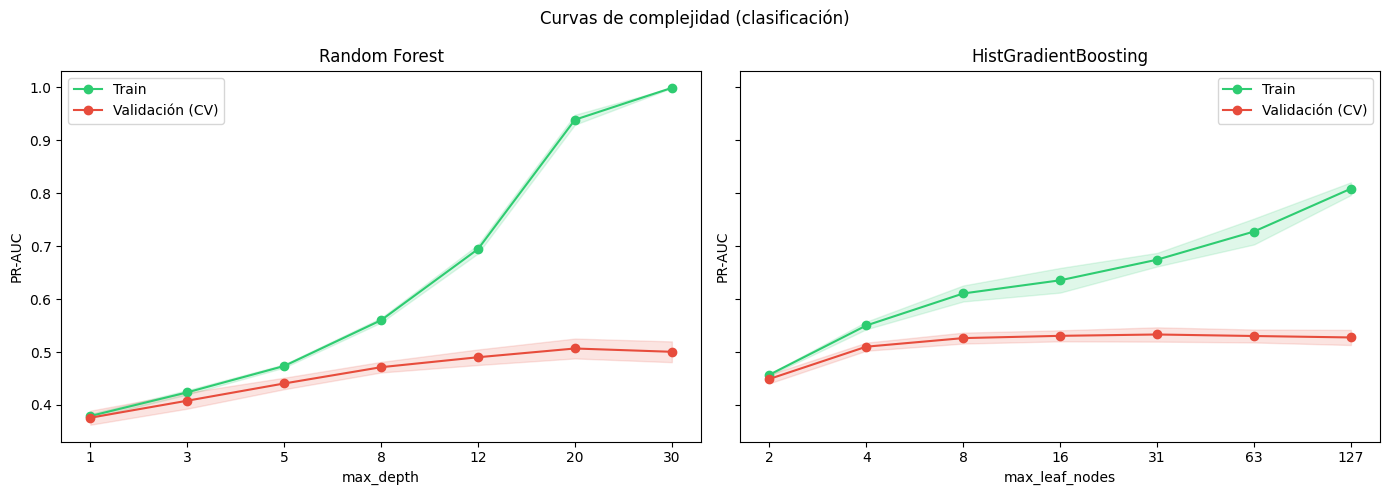

In [ ]:
def curva_complejidad(ax, modelo, param, valores, titulo):
    tr, va = validation_curve(build_pipeline(modelo), X_dev, y_dev,
                              param_name=f"model__{param}", param_range=valores,
                              cv=CV, scoring=SCORE)
    x = range(len(valores))
    for m, lab, c in [(tr, "Train", "#2ecc71"), (va, "Validación (CV)", "#e74c3c")]:
        ax.plot(x, m.mean(1), "o-", color=c, label=lab)
        ax.fill_between(x, m.mean(1) - m.std(1), m.mean(1) + m.std(1), color=c, alpha=.15)
    ax.set_xticks(x)
    ax.set_xticklabels(valores)
    ax.set_xlabel(param)
    ax.set_ylabel("PR-AUC")
    ax.set_title(titulo)
    ax.legend()
    return va

CURVAS = {   # nombre: (modelo, parámetro de complejidad, valores)
    "Random Forest":       (RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1),
                            "max_depth", [1, 3, 5, 8, 12, 20, 30]),        # 30 equivale a "sin límite"
    "HistGradientBoosting": (hgb, "max_leaf_nodes", [2, 4, 8, 16, 31, 63, 127]),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (nombre, (modelo, param, valores)) in zip(axes, CURVAS.items()):
    va = curva_complejidad(ax, modelo, param, valores, nombre)
    i = va.mean(1).argmax()
    print(f"{nombre}: máximo de validación en {param}={valores[i]} "
          f"({va.mean(1)[i]:.3f} ± {va.std(1)[i]:.3f})")
plt.suptitle("Curvas de complejidad (clasificación)")
plt.tight_layout()
plt.show()

# Qué muestran las curvas de complejidad

Las curvas responden una pregunta: **¿cuánta flexibilidad le conviene tener a cada modelo?** Cada punto es un valor distinto del parámetro que regula la complejidad:

- **Random Forest:** `max_depth` (cuántas preguntas en cadena puede hacer cada árbol).
- **HistGradientBoosting (HGB):** `max_leaf_nodes` (cuántas regiones puede distinguir cada árbol).

La línea verde es el PR-AUC sobre los datos con los que se entrenó y la roja es el PR-AUC sobre los folds que el modelo no vio. Las bandas son el desvío entre los 5 folds. Como los parámetros y las escalas son distintos, se comparan la **forma** y la **altura máxima** de las curvas, no las posiciones sobre el eje X.

## Random Forest: cómo leerlo por zonas

| Zona | Qué se ve | Diagnóstico |
|---|---|---|
| `max_depth` 1 a 5 | Train y validación casi pegadas (~0,38 a ~0,44) y ambas todavía subiendo | **Underfitting (sesgo alto):** el árbol es tan chico que no alcanza a capturar la estructura del problema. Dar más profundidad ayuda mucho |
| `max_depth` 8 a 12 | Validación sigue subiendo (~0,47 a ~0,49), pero train despega (0,56 a 0,69) | **Transición:** el modelo gana capacidad y empieza a abrirse la brecha entre lo que memoriza y lo que generaliza |
| `max_depth` 20 a 30 | Train llega a ~0,94 y 1,0; validación se estanca en ~0,50 | **Meseta:** más profundidad ya no mejora lo que importa. A 30 el modelo memoriza el train por completo |

## HGB: cómo leerlo por zonas

| Zona | Qué se ve | Diagnóstico |
|---|---|---|
| `max_leaf_nodes` 2 a 4 | Validación sube rápido (~0,45 a ~0,51); train y validación todavía cercanas | **Underfitting:** con 2 hojas cada árbol hace un solo corte, así que el modelo es aditivo (suma efectos de una variable por vez). Permitir 4 hojas ya habilita interacciones |
| `max_leaf_nodes` 8 a 63 | Validación prácticamente plana (~0,526 a ~0,533); train sigue subiendo (0,61 a 0,73) | **Meseta temprana:** más complejidad por árbol no mejora lo que generaliza. La brecha crece de forma gradual |
| `max_leaf_nodes` 127 | Train llega a ~0,81; validación ~0,527 | **Sobreajuste leve:** la brecha es la mayor del panel, pero la validación casi no cae |

## Cinco cosas a tener en cuenta

1. **En el Random Forest, el óptimo está en profundidad alta (~20), no en 8 a 12.** La validación sube hasta 20 y entre 20 y 30 las diferencias quedan dentro de la banda de ruido, así que 20 y 30 son prácticamente equivalentes.

2. **En HGB, la validación llega más alto y con mucha menos complejidad.** Con solo 8 hojas por árbol ya supera (~0,526) al mejor punto del Random Forest (~0,507). Es una pista fuerte a favor de HGB, pero con una salvedad: las curvas no comparan en igualdad de condiciones (el Random Forest usa 50 árboles y `min_samples_leaf=1`, HGB usa sus valores por defecto con early stopping). La comparación que decide es la tabla de la sección 5, con los mismos folds para todos los modelos.

3. **La brecha entre train y validación es mucho menor en HGB.** En el Random Forest llega a 1,0 contra ~0,50; en HGB a ~0,81 contra ~0,53. Ambos "memorizan" parte del train, pero ninguno ve caer la validación. En los dos casos el overfitting se manifiesta como **brecha**, no como caída de la curva roja. Lo que decide es dónde deja de mejorar la roja, no qué tan grande es la verde.

4. **Ya con un solo corte por árbol hay señal.** El Random Forest con `max_depth=1` rinde ~0,38 y HGB con 2 hojas ~0,45, ambos bastante por encima de la prevalencia que imprimió tu sección 2 (el piso). Hipótesis a verificar: algunas variables, probablemente `availability_365`, separan casi solas a los inactivos. La comparación con y sin esa variable de la sección 6 lo confirma.

5. **El salto de HGB entre 2 y 4 hojas (~0,45 a ~0,51) es un indicio de interacciones.** Con 2 hojas el modelo solo suma efectos individuales de cada variable; con 4 puede combinar variables. Es evidencia a favor de que hay estructura no aditiva (por ejemplo disponibilidad combinada con precio o ubicación). Contrastalo con la Logística + bins de la sección 5: si ella queda cerca de lo que logra HGB con 2 hojas, lo que aportan las interacciones es la diferencia que falta hasta ~0,53.

# Los valores óptimos

## Random Forest: alrededor de `max_depth` 20

Es donde la validación alcanza su máximo (~0,51), con dos matices.

**Entre 20 y 30 no hay diferencia real.** La validación pasa de ~0,507 en 20 a ~0,50 en 30, pero las bandas se superponen casi por completo. Si dos valores rinden igual, conviene el más barato: **20 es mejor que 30 (o `None`)** porque los árboles son más chicos, entrenan más rápido y pesan menos.

**La regla de un desvío estándar apunta más abajo.** Es la misma regla de la sección 7 (elegir la opción más simple dentro de un desvío del mejor):

- Mejor valor: ~0,507 (en 20).
- Desvío entre folds: ~0,015 (el ancho de la banda en ese punto).
- Piso: ~0,49.

El punto 12 (~0,49) roza ese piso, 16 (que no está en el gráfico) debería quedar entre 12 y 20, y 8 (~0,47) queda claramente afuera. El candidato parsimonioso está **entre 12 y 16**.

## HGB: alrededor de `max_leaf_nodes` 31, con candidato parsimonioso en 8

El máximo está en torno a 31 hojas (~0,533), que además es el valor por defecto de sklearn. Pero la curva es muy plana desde 8 hasta 127.

- Mejor valor: ~0,533 (en 31).
- Desvío entre folds: ~0,01.
- Piso: ~0,52.

Con 8 hojas (~0,526) ya se está dentro del piso, mientras que 4 (~0,51) queda justo afuera. Aplicando la regla, el candidato parsimonioso es **8 hojas**: árboles más chicos, más rápidos de entrenar y con una brecha de sobreajuste menor.

## Conclusión práctica

| Criterio | Random Forest (`max_depth`) | HGB (`max_leaf_nodes`) |
|---|---|---|
| Máximo de la curva | 20 | ~31 |
| Más simple dentro de un desvío | 12 a 16 | ~8 |
| Rango a descartar (subajusta) | 1 a 8 | 2 a 4 |
| Rango sugerido para el tuner | `[12, 16, 20, None]` | `[8, 16, 31]` |

**Mi recomendación:** no cierres el valor con estas curvas. Usalas para acotar el rango y dejá que el tuner decida. En el espacio de HGB conviene cambiar `max_leaf_nodes` de `[15, 31, 63]` a `[8, 16, 31]`: la curva muestra que valores altos no aportan nada, mientras que los bajos sí merecen probarse. Siguen siendo 27 combinaciones.

## Por qué no son "el" óptimo definitivo

- **Cada curva varía un solo hiperparámetro** y deja el resto fijo (en el Random Forest `min_samples_leaf=1`, `max_features` por defecto y 50 árboles; en HGB `learning_rate=0.1` y `min_samples_leaf=20`). Los hiperparámetros interactúan: con un `min_samples_leaf` mayor, los árboles ya no pueden memorizar y una complejidad alta deja de ser tan "riesgosa". Por eso el valor final sale de la búsqueda conjunta de la sección 9.
- **Los números de este texto están leídos a ojo del gráfico.** Para precisión, usá los máximos que imprime la celda (`valor ± desvío`) o imprimí `va.mean(1)` y `va.std(1)` junto a los valores del eje.
- **La elección del modelo no se decide acá.** Estas curvas ilustran cómo se comporta cada modelo al variar su complejidad. Qué modelo se tunea lo define la tabla de la sección 5 con la regla de la sección 7.



# Qué es el PR-AUC

## Las dos piezas

Para un umbral dado, el modelo marca como "inactivos" a los avisos con probabilidad por encima del corte:

- **Precisión:** de los que marco, ¿qué fracción es realmente inactiva? (el costo de auditar de más)
- **Recall:** de todos los inactivos reales, ¿qué fracción logro marcar? (el costo de dejar escapar casos)

Subir el umbral hace que marques menos avisos y más seguros: sube la precisión y baja el recall. Bajarlo hace lo contrario. Si se recorren todos los umbrales posibles y se grafica precisión contra recall, se obtiene la **curva precisión-recall**. El **PR-AUC es el área bajo esa curva**.

## Cómo se calcula (`average_precision`)

Sklearn usa una versión escalonada: ordena los avisos de mayor a menor probabilidad y promedia la precisión en cada punto donde aparece un inactivo real, ponderada por cuánto sube el recall:

$$AP = \sum_n (R_n - R_{n-1})\, P_n$$

**Ejemplo mínimo.** Diez avisos ordenados por probabilidad, con 3 inactivos reales en las posiciones 1, 3 y 4:

| Posición donde aparece un inactivo | Precisión en ese punto |
|---|---|
| 1 | 1/1 = 1,00 |
| 3 | 2/3 = 0,67 |
| 4 | 3/4 = 0,75 |

El promedio es (1 + 0,67 + 0,75) / 3 ≈ **0,81**. Si los tres inactivos hubieran quedado primeros, daría 1,0. Si estuvieran dispersos al final de la lista, daría un valor bajo. En una frase: **mide qué tan arriba del ranking quedan los inactivos reales**.

## Cómo interpretar el valor

- **Piso:** un modelo sin información da un PR-AUC igual a la **prevalencia** (la proporción de inactivos). Por eso el Dummy sirve de referencia. Con prevalencia de 0,20, un PR-AUC de 0,50 significa que el modelo ordena notablemente mejor que el azar, y se puede decir "2,5 veces mejor que elegir al azar" con tus números reales.
- **Techo:** 1,0 es un ranking perfecto.
- **No es una probabilidad ni un porcentaje de aciertos.** Es un resumen del ranking.

## Por qué se eligió sobre el ROC-AUC y el accuracy

| Métrica | Problema en este caso |
|---|---|
| Accuracy | Con 80% de activos, predecir siempre "activo" da 80% sin detectar ningún inactivo |
| ROC-AUC | Mezcla los aciertos sobre los activos (la clase mayoritaria) con los de interés, y puede verse alta aunque la precisión práctica sea baja |
| **PR-AUC** | Mira solo qué pasa con la clase que importa, y su valor se traduce a negocio: "si audito los avisos mejor puntuados, ¿qué proporción de inactivos encuentro?" |

Además es independiente del umbral: evalúa el ranking completo, y el corte se decide después (sección 10 del notebook) según cuánta precisión mínima exija el negocio.

## Un detalle sobre tu gráfico

El PR-AUC de **train** de 1,0 en `max_depth=30` es esperable e inofensivo: significa que el modelo ordena perfectamente los avisos que ya vio. Nunca se reporta como resultado, solo sirve para visualizar la memorización. El número que cuenta es el de validación, ~0,50.

## 9. Tuning con dos métodos: RandomizedSearchCV y Optuna (Eje 3)

Los dos tuners comparten **el mismo espacio y el mismo presupuesto** (10 iteraciones, 5 folds cada una), así la comparación es justa. Reciben el espacio como argumento, por lo que sirven para cualquier modelo.

**Espacios (reducidos por YAGNI):**
- **Random Forest** (32 combinaciones): `n_estimators` queda fijo en 200, porque más árboles nunca empeoran el modelo y solo cuestan tiempo. `min_samples_split` se elimina porque se solapa con `min_samples_leaf`. Entra `max_features`, que suele importar más.
- **Logística** (5 valores): solo `C`. Con 5 combinaciones el presupuesto se limita a 5.

In [ ]:
RF_SPACE = {
    "model__max_depth":        [8, 12, 16, None],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features":     ["sqrt", 0.5],
}
HGB_SPACE = {
    "model__learning_rate":    [0.05, 0.1, 0.2],
    "model__max_leaf_nodes":   [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
}
LR_SPACE = {"model__C": [0.01, 0.1, 1, 10, 100]}

SPACES = {"Logistica": LR_SPACE, "Logistica + bins": LR_SPACE, "HGB": HGB_SPACE, "RF": RF_SPACE}

def budget(space):                       # nunca más iteraciones que combinaciones
    return int(min(N_TRIALS, np.prod([len(v) for v in space.values()])))

def _para_buscar(pipe, n_estimators=50):
    p = clone(pipe)
    for k, v in {"model__n_jobs": 1, "model__n_estimators": n_estimators}.items():
        if k in p.get_params():                           # solo si el modelo lo tiene
            p.set_params(**{k: v})
    return p

def _n_jobs(pipe):                       # RF y Logística: la búsqueda paraleliza; HGB ya usa todos los núcleos por dentro
    return -1 if "model__n_jobs" in pipe.get_params() else 1

def tune_random(pipe, space, X, y):
    s = RandomizedSearchCV(_para_buscar(pipe), space, n_iter=budget(space), cv=CV,
                           scoring=SCORE, random_state=SEED, n_jobs=_n_jobs(pipe),
                           verbose=1, refit=False).fit(X, y)

    t = pd.DataFrame(s.cv_results_)
    t["params"] = t.params.apply(lambda d: {k.split("__")[1]: v for k, v in d.items()})
    cols = ["params", "mean_test_score", "std_test_score", "mean_fit_time"]
    print(t.sort_values("rank_test_score")[cols].round(3).to_string(index=False))

    return clone(pipe).set_params(**s.best_params_).fit(X, y), s.best_score_

def tune_optuna(pipe, space, X, y):
    def objective(trial):
        params = {k: trial.suggest_categorical(k, v) for k, v in space.items()}
        return cross_val_score(_para_buscar(pipe).set_params(**params), X, y,
                               cv=CV, scoring=SCORE, n_jobs=_n_jobs(pipe)).mean()

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=5))
    study.optimize(objective, n_trials=budget(space))
    return clone(pipe).set_params(**study.best_params).fit(X, y), study.best_value

In [ ]:
print(f"HyperTuning del modelo : {elegido}")

HyperTuning del modelo : HGB


In [ ]:
pipe = modelos[elegido]
print(f"HyperTuning del modelo: {elegido}")

HyperTuning del modelo: HGB


In [ ]:
print("HyperTuning con RandomSearch")
best_model, cv_model = tune_random(pipe, SPACES[elegido], X_dev, y_dev)
print(f"PR-AUC CV -> {elegido}: {cv_model:.3f}" #| Optuna: {cv_op:.3f} "
      f"| {elegido} sin tunear: {pr[elegido].mean():.3f}")

HyperTuning con RandomSearch
Fitting 5 folds for each of 10 candidates, totalling 50 fits
                                                                params  mean_test_score  std_test_score  mean_fit_time
  {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'learning_rate': 0.1}            0.534           0.012          1.378
{'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'learning_rate': 0.05}            0.534           0.012          2.937
  {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'learning_rate': 0.1}            0.533           0.013          1.255
 {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'learning_rate': 0.1}            0.533           0.013          3.551
  {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'learning_rate': 0.1}            0.531           0.013          3.601
 {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.1}            0.530           0.013          1.586
  {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.1}       

In [ ]:
print("HyperTuning con Optuna")
best_op, cv_op = tune_optuna(pipe, SPACES[elegido], X_dev, y_dev)

print(f"PR-AUC CV -> | Optuna: {cv_op:.3f} "
      f"| {elegido} sin tunear: {pr[elegido].mean():.3f}")

[I 2026-10-28 08:54:47,990] A new study created in memory with name: no-name-d7b08b32-07cd-4157-8501-88d5deb7b0a3


HyperTuning con Optuna


[I 2026-10-28 08:54:56,084] Trial 0 finished with value: 0.5343527350420791 and parameters: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 50}. Best is trial 0 with value: 0.5343527350420791.
[I 2026-10-28 08:55:02,108] Trial 1 finished with value: 0.5291657151004208 and parameters: {'model__learning_rate': 0.2, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 100}. Best is trial 0 with value: 0.5343527350420791.
[I 2026-10-28 08:55:09,401] Trial 2 finished with value: 0.525289248809816 and parameters: {'model__learning_rate': 0.2, 'model__max_leaf_nodes': 63, 'model__min_samples_leaf': 50}. Best is trial 0 with value: 0.5343527350420791.
[I 2026-10-28 08:55:17,743] Trial 3 finished with value: 0.5343527350420791 and parameters: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 50}. Best is trial 0 with value: 0.5343527350420791.
[I 2026-10-28 08:55:23,047] Trial 4 finished with value: 0.525289248809816 a

PR-AUC CV -> | Optuna: 0.534 | HGB sin tunear: 0.533


## 11. Evaluación única y final sobre el test (Eje 3, punto 4)

El test se usa **una sola vez** y no decide nada: solo informa. Se evalúa el baseline (Logística simple) y el modelo final con el umbral de negocio.

In [ ]:
def elegir_umbral(y_true, p, objetivos=(0.60, 0.50, 0.40, 0.30)):
    prec, rec, thr = precision_recall_curve(y_true, p)
    for obj in objetivos:
        ok = prec[:-1] >= obj
        if ok.any():
            return thr[ok][np.argmax(rec[:-1][ok])], obj, rec[:-1][ok].max()
    raise ValueError("Ningún umbral alcanza ni siquiera 30% de precisión en CV.")


final, cv_final = max([(best_model, cv_model), (best_op, cv_op)], key=lambda t: t[1])

oof = cross_val_predict(clone(final), X_dev, y_dev, cv=CV, method="predict_proba")[:, 1]
umbral, precision_lograda, recall_esperado = elegir_umbral(y_dev, oof)

if precision_lograda < 0.60:
    print(f"Aviso: 60% de precisión no es alcanzable; se usa el objetivo de {precision_lograda:.0%}.")
print(f"Umbral: {umbral:.3f} | precisión objetivo >= {precision_lograda:.0%} "
      f"| recall esperado: {recall_esperado:.2f}")


Umbral: 0.447 | precisión objetivo >= 60% | recall esperado: 0.34


In [ ]:
from sklearn.metrics import precision_score, recall_score   # sumar al import de la sección 1

def evaluate(nombre, modelo, thr=0.5):
    p = modelo.predict_proba(X_test)[:, 1]
    pred = (p >= thr).astype(int)
    print(f"\n=== {nombre} | ROC-AUC {roc_auc_score(y_test, p):.3f} "
          f"| PR-AUC {average_precision_score(y_test, p):.3f} | umbral {thr:.3f}")
    print(classification_report(y_test, pred, target_names=["activo", "inactivo"]))
    print(confusion_matrix(y_test, pred))

# Comparación independiente del umbral: baseline, modelo elegido sin tunear y tuneado
candidatos = {
    "Logistica sin tunear":  clone(modelos["Logistica"]).fit(X_dev, y_dev),
    f"{elegido} sin tunear": clone(modelos[elegido]).fit(X_dev, y_dev),
    f"{elegido} tuneado":    best_model,
}

def auc_test(modelo):
    p = modelo.predict_proba(X_test)[:, 1]
    return {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)}

print(pd.DataFrame({n: auc_test(m) for n, m in candidatos.items()}).T.round(3))

# 2) Informe detallado del modelo final con el umbral de negocio
evaluate(f"Final ({elegido}, tuneado)", best_model, thr=umbral)

# 3) ¿Se sostuvo en test lo que prometió la validación cruzada?
pred = best_model.predict_proba(X_test)[:, 1] >= umbral
print(f"\nPrecisión: objetivo CV >= {precision_lograda:.0%} | observada en test: {precision_score(y_test, pred):.3f}")
print(f"Recall:    esperado CV {recall_esperado:.2f} | observado en test: {recall_score(y_test, pred):.3f}")

                      ROC-AUC  PR-AUC
Logistica sin tunear    0.642   0.354
HGB sin tunear          0.777   0.526
HGB tuneado             0.780   0.528

=== Final (HGB, tuneado) | ROC-AUC 0.780 | PR-AUC 0.528 | umbral 0.447
              precision    recall  f1-score   support

      activo       0.84      0.94      0.88      4550
    inactivo       0.59      0.34      0.43      1242

    accuracy                           0.81      5792
   macro avg       0.71      0.64      0.66      5792
weighted avg       0.78      0.81      0.79      5792

[[4259  291]
 [ 824  418]]

Precisión: objetivo CV >= 60% | observada en test: 0.590
Recall:    esperado CV 0.34 | observado en test: 0.337


**Cómo leerlo:**
- ROC-AUC y PR-AUC no dependen del umbral: se comparan entre baseline y final, y contra el piso del Dummy (0,5 y la prevalencia).
- En el `classification_report` del modelo final, la **precisión de `inactivo`** responde "de los avisos que marco, qué porcentaje lo es realmente" y el **recall** responde "qué porcentaje de los inactivos reales encuentro". Es el equivalente interpretable del "MAE en ARS" de la clase de regresión.
- La matriz de confusión (filas = real, columnas = predicho) permite contar cuántos avisos se auditarían de más.

El modelo **HistGradientBoosting (HGB) tuneado** logra un desempeño general aceptable, pero muestra un comportamiento muy asimétrico debido al desbalance entre clases (4,550 activos vs. 1,242 inactivos).

---

### 1. Métricas Globales y Discriminación General

* **ROC-AUC (0.780) y PR-AUC (0.528):** El modelo superó de forma consistente a la regresión logística (0.642 / 0.354). Un ROC-AUC de 0.780 indica una capacidad moderada-alta para ordenar los casos por nivel de riesgo o probabilidad de inactividad. Sin embargo, el ajuste de hiperparámetros respecto a la versión sin tunear aportó una mejora marginal (+0.003 en ROC-AUC y +0.002 en PR-AUC).

### 2. Rendimiento en la Clase de Interés (`inactivo`)

* **Recall (Sensibilidad) de 33.7% (418 de 1,242):** El modelo solo logra capturar a 1 de cada 3 clientes inactivos. Fuga o no detecta al **66.3% restante** (824 inactivos que se clasificaron erróneamente como activos).
* **Precisión de 59.0% (418 de 709):** Cuando el modelo predice que un cliente estará "inactivo", acierta en casi 6 de cada 10 casos. Los 291 casos restantes fueron falsos positivos.

### 3. Generalización y Consistencia (CV vs. Test)

* **Alta consistencia y bajo sobreajuste:** El Recall observado en test (**33.7%**) replica casi a la perfección lo esperado en Validación Cruzada (**34.0%**). La Precisión del 59.0% se mantiene muy cercana al objetivo fijado en CV ($\ge 60\%$). Esto confirma que la estimación durante el entrenamiento fue rigurosa y libre de data leakage significativo.

---

### Matriz de Confusión resumida

| Real \ Predicho | Predicho Activo | Predicho Inactivo | Total |
| --- | --- | --- | --- |
| **Real Activo** | **4,259** (Verdaderos Negativos) | **291** (Falsos Positivos) | 4,550 |
| **Real Inactivo** | **824** (Falsos Negativos) | **418** (Verdaderos Positivos) | 1,242 |

---

### Implicaciones Prácticas y Estratégicas

1. **Trade-off del umbral actual (0.447):** El umbral seleccionado prioriza mantener la precisión en ~60% a costa de sacrificar Recall. Esto es adecuado si las acciones preventivas (ej. ofrecer promociones o retención) son costosas y no se desea impactar a clientes activos por error.
2. **Costo de los Falsos Negativos:** Si el costo de perder a un cliente inactivo no detectado (824 casos) es mayor que el costo de contactar a un cliente activo por error (291 casos), el umbral de 0.447 resulta demasiado conservador y **debería bajarse** (ej. a 0.30 o 0.35) para capturar más inactivos.

## 12. Demostración con avisos de ejemplo

En lugar del intervalo de predicción de regresión, la salida natural es la **probabilidad de estar inactivo** y la decisión de auditar según el umbral.

In [ ]:
demo = pd.DataFrame([
    dict(name="Casabierta, Palermo", neighbourhood="Palermo", room_type="Entire home/apt",
         latitude=-34.58718, longitude=-58.4312, price=415838, minimum_nights=2,
         calculated_host_listings_count=1, availability_365=232),
    dict(name="Flat en La Boca", neighbourhood="Boca", room_type="Entire home/apt",
         latitude=-34.63255, longitude=-58.35777, price=52258, minimum_nights=7,
         calculated_host_listings_count=1, availability_365=355),
    dict(name="Lilac Suite, Constitucion", neighbourhood="Constitucion", room_type="Private room",
         latitude=-34.61954, longitude=-58.38417, price=77206, minimum_nights=2,
         calculated_host_listings_count=6, availability_365=90),
    dict(name="Penthouse, Recoleta", neighbourhood="Recoleta", room_type="Entire home/apt",
         latitude=-34.58838, longitude=-58.38925, price=457552, minimum_nights=7,
         calculated_host_listings_count=2, availability_365=135),
])
demo = demo.assign(log_price=np.log1p(demo.price))

demo["p_inactivo"] = final.predict_proba(demo)[:, 1].round(3)
demo["auditar"] = demo.p_inactivo >= umbral
print(demo[["name", "p_inactivo", "auditar"]])

                        name  p_inactivo  auditar
0        Casabierta, Palermo       0.075    False
1            Flat en La Boca       0.496     True
2  Lilac Suite, Constitucion       0.290    False
3        Penthouse, Recoleta       0.377    False


**Nota:** el pipeline recibe el DataFrame completo; `ColumnTransformer` ignora las columnas que no usa (`name`, `price`). Un barrio no visto en entrenamiento no rompe nada gracias a `handle_unknown="ignore"`.

## 13. Anti-patrones y cierre

**Anti-patrones que este notebook evita (y cómo):**

| Anti-patrón | Cómo se previene aquí |
|---|---|
| Fuga por definición del target | Se excluyen todas las variables de reviews (sección 3) |
| Fuga por preprocesamiento | Imputación, escalado y discretización dentro del `Pipeline` (sección 4) |
| Decidir mirando el test | Curva, tuning, elección de modelo y umbral usan solo `X_dev`; el test se usa una vez (sección 11) |
| Accuracy engañoso | Dummy como piso; métricas PR-AUC, ROC-AUC y precisión/recall |
| Umbral arbitrario | Umbral elegido por regla de negocio sobre predicciones out-of-fold |

**Extensiones y limitaciones para discutir:**
1. **Group leakage:** un host con muchos avisos casi idénticos puede quedar repartido entre train y validación. La mejora es reemplazar `CV` por `StratifiedGroupKFold` con `host_id` como grupo. Implica conservar `host_id` fuera de `X` y pasar `groups=` a `cross_validate`, `cross_val_score`, `cross_val_predict`, `validation_curve` y `RandomizedSearchCV.fit`.
2. **Temporalidad:** `number_of_reviews_ltm` depende de la fecha de captura del dataset. El modelo describe ese corte, no predice el futuro.
3. **Descriptivo, no causal:** el modelo identifica avisos con perfil de inactivos, no explica por qué lo están (ver sección 6).
4. **Información faltante:** no hay ratings, amenities ni fotos. Agregarlos es el siguiente paso si el rendimiento resulta bajo.
5. **Ejercicio propuesto:** repetir el notebook con otro target definido por reglas (por ejemplo "alta demanda" por cuartil superior de reviews, calculando el corte **solo con train**), cambiando solo la línea de `y` y las columnas excluidas.

**Resumen para entregar a los alumnos**

| Componente | Elección | Justificación |
|---|---|---|
| Target | `inactivo` = `reviews_ltm == 0` | Accionable y definido por regla de negocio |
| Validación | `StratifiedKFold` (5, shuffle) | Mantiene la proporción de la clase minoritaria |
| Preprocesamiento | `Pipeline` + `ColumnTransformer` | Aislamiento entre folds, sin fuga |
| Selección de modelo | Logística, Logística + bins y Random Forest; regla de un desvío estándar | Elige el modelo más simple que rinde y responde si el problema es lineal |
| Optimización | `RandomizedSearchCV` y Optuna, mismo espacio y 10 iteraciones | Comparación justa con presupuesto mínimo |
| Métrica de tuning | PR-AUC | Foco en la clase minoritaria, independiente del umbral |
| Umbral | Máximo recall con precisión >= 60% (baja a 50, 40 y 30%) en out-of-fold | El test no participa en ninguna decisión |
| Métricas finales | ROC-AUC, PR-AUC, precisión/recall/F1, matriz de confusión | Una estadística y una interpretable para negocio |